# JC 主线：2025 留出期确认
此 Notebook 只读取已冻结的一次性评估结果，不训练模型、不重跑最终评估。
重要限制：早期探索脚本曾计算并显示过一次 2025 指标，虽然未用于调参，因此这不是完全未触碰的盲测。

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
metrics = pd.read_csv(ROOT / 'results/metrics/jc_final_2025_metrics.csv')
metadata = json.loads((ROOT / 'results/metrics/jc_final_2025_metadata.json').read_text(encoding='utf-8'))
predictions = pd.read_csv(ROOT / 'results/metrics/jc_final_2025_common_predictions.csv', parse_dates=['predictor_time_utc'])
display(metrics)
print('common scored rows:', metadata['common_scored_rows'])
print('holdout pristine:', metadata['holdout_pristine'])
print(metadata['holdout_caveat'])

,model,n,MAE,RMSE,R2
0,random_forest,8590,14.958104,23.600408,0.942846
1,random_forest_weather,8590,15.105848,23.829352,0.941731
2,lstm_168h,8590,15.125756,22.559564,0.947776
3,mlp,8590,16.010280,24.479869,0.938507
4,linear_regression_weather,8590,21.718103,31.403541,0.898803
5,linear_regression,8590,21.849332,32.446720,0.891968
6,naive_previous_week,8590,29.724796,48.745957,0.756170
7,naive_previous_hour,8590,35.121886,52.066776,0.721816


common scored rows: 8590
holdout pristine: False
An earlier exploratory script evaluated and displayed 2025 metrics; those values were excluded from tuning, but the holdout is not a pristine blind test.


## 测试期曲线
以下只展示预测与实际值，不作测试集驱动的调参。最终候选比较结束后不再修改特征或模型配置。

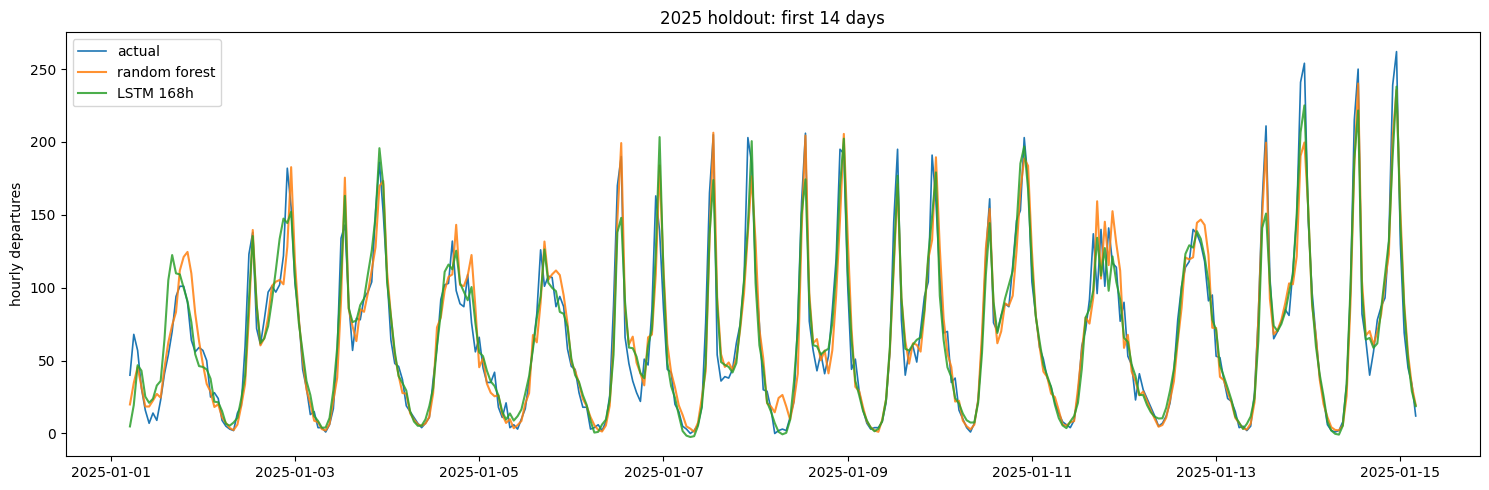

In [2]:
predictions['target_time_utc'] = pd.to_datetime(predictions['predictor_time_utc'], utc=True) + pd.Timedelta(hours=1)
sample = predictions.loc[predictions['target_time_utc'] < predictions['target_time_utc'].min() + pd.Timedelta(days=14)]
plt.figure(figsize=(15,5))
plt.plot(sample['target_time_utc'], sample['actual'], label='actual', linewidth=1.2)
plt.plot(sample['target_time_utc'], sample['random_forest'], label='random forest', alpha=.85)
plt.plot(sample['target_time_utc'], sample['lstm_168h'], label='LSTM 168h', alpha=.85)
plt.legend(); plt.ylabel('hourly departures'); plt.title('2025 holdout: first 14 days'); plt.tight_layout()
plt.savefig(ROOT / 'results/figures/jc_final_2025_first_14_days.png', dpi=150, bbox_inches='tight')
plt.show()